In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib, os

X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train = pd.read_csv("../data/processed/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../data/processed/y_test.csv").squeeze("columns")

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True))

(107740, 42) (55945, 42)
label
1    0.518378
0    0.481622
Name: proportion, dtype: float64


In [2]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
pred_rf = rf.predict(X_test)

In [3]:
from xgboost import XGBClassifier

xgb = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=6,
                    random_state=42, n_jobs=-1)
xgb.fit(X_train, y_train)
pred_xgb = xgb.predict(X_test)

In [4]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

for name, pred in [("Random Forest", pred_rf), ("XGBoost", pred_xgb)]:
    print("=====", name, "=====")
    print(classification_report(y_test, pred, target_names=["Normal", "Attaque"]))

===== Random Forest =====
              precision    recall  f1-score   support

      Normal       0.98      0.74      0.84     34206
     Attaque       0.71      0.98      0.82     21739

    accuracy                           0.83     55945
   macro avg       0.84      0.86      0.83     55945
weighted avg       0.87      0.83      0.83     55945

===== XGBoost =====
              precision    recall  f1-score   support

      Normal       0.97      0.75      0.85     34206
     Attaque       0.71      0.97      0.82     21739

    accuracy                           0.83     55945
   macro avg       0.84      0.86      0.83     55945
weighted avg       0.87      0.83      0.84     55945



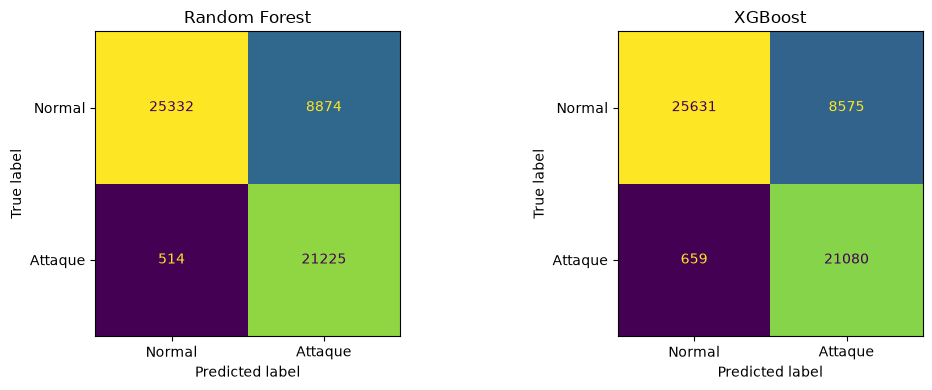

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, pred) in zip(axes, [("Random Forest", pred_rf), ("XGBoost", pred_xgb)]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                           display_labels=["Normal", "Attaque"]).plot(ax=ax, colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

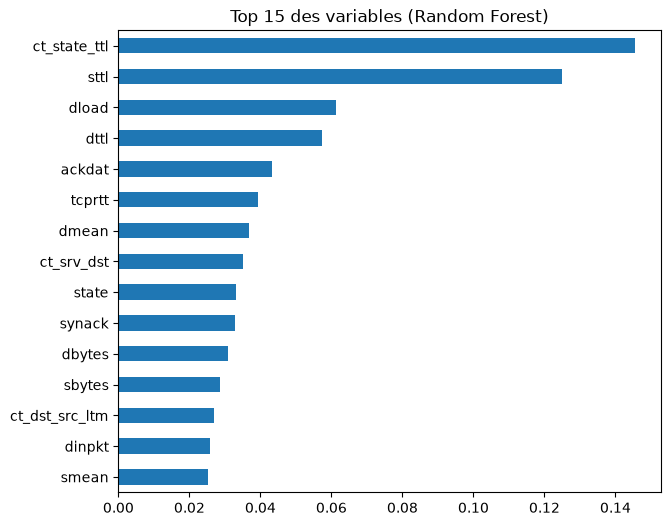

In [6]:
imp = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values().tail(15)
imp.plot(kind="barh", figsize=(7, 6), title="Top 15 des variables (Random Forest)")
plt.show()

In [7]:
os.makedirs("../models", exist_ok=True)
joblib.dump(rf, "../models/random_forest.joblib")
joblib.dump(xgb, "../models/xgboost.joblib")

['../models/xgboost.joblib']

## Résultats

| Modèle | Precision | Recall | F1 |
|---|---|---|---|
| Random Forest | X | X | X |
| XGBoost | X | X | X |

**Observations :** quel modèle détecte le mieux les attaques, combien de faux positifs et de faux négatifs, quelles variables dominent.

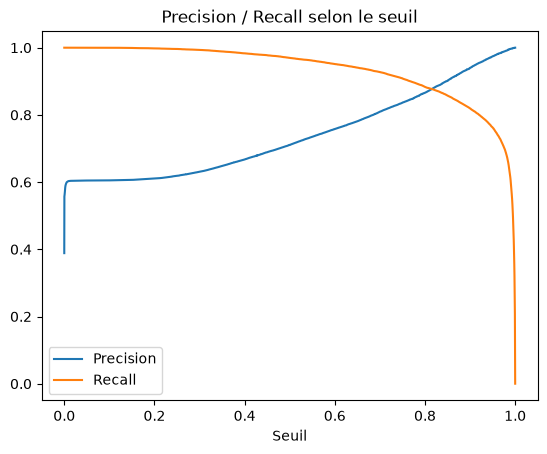

In [8]:
from sklearn.metrics import precision_recall_curve, classification_report

proba = xgb.predict_proba(X_test)[:, 1]
prec, rec, thr = precision_recall_curve(y_test, proba)

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.xlabel("Seuil")
plt.legend()
plt.title("Precision / Recall selon le seuil")
plt.show()

In [9]:
pred_07 = (proba >= 0.7).astype(int)
print(classification_report(y_test, pred_07, target_names=["Normal", "Attaque"]))

              precision    recall  f1-score   support

      Normal       0.95      0.86      0.90     34206
     Attaque       0.81      0.93      0.86     21739

    accuracy                           0.89     55945
   macro avg       0.88      0.89      0.88     55945
weighted avg       0.89      0.89      0.89     55945



In [10]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(xgb, X_train, y_train, cv=5, scoring="f1")
print(scores, scores.mean())

[0.91773413 0.95554118 0.96417088 0.9489603  0.69880881] 0.8970430601282577


## Résultats et conclusion

**Modèles comparés** (seuil de décision par défaut : 0,5)

| Modèle | Precision (Attaque) | Recall (Attaque) | F1 (Attaque) | Accuracy |
|---|---|---|---|---|
| Random Forest | 0,71 | 0,98 | 0,82 | 0,83 |
| XGBoost | 0,71 | 0,97 | 0,82 | 0,83 |

**Effet du seuil de décision** (XGBoost)

| Seuil | Precision (Attaque) | Recall (Attaque) |
|---|---|---|
| 0,5 | 0,71 | 0,97 |
| 0,7 | X | X |

**Validation croisée (5 plis, XGBoost sur le train) :** F1 moyen = X

**Observations**
- Les deux modèles se valent. Le Recall élevé (97-98 %) montre que presque toutes
  les attaques sont détectées.
- Environ 26 % du trafic normal est signalé à tort comme attaque (faux positifs),
  ce qui limite la Precision à 0,71.
- UNSW-NB15 fournit des fichiers train et test à distributions différentes :
  l'écart avec la validation croisée (X) l'illustre.
- Dans un contexte défensif, on privilégie le Recall (ne rien manquer), au prix
  de davantage de fausses alertes à trier par l'analyste.

**Limites et suite :** analyse par type d'attaque, réduction des faux positifs,
puis tableau de bord et explication des alertes par un LLM local.